# Give Me Some Credit — Credit Scorecard & Model Validation

Mô hình ước tính xác suất khách hàng quá hạn từ 90 ngày trở lên trong vòng hai năm (`SeriousDlqin2yrs`). Quy trình gồm kiểm tra dữ liệu, xây dựng scorecard bằng Logistic Regression, đối chiếu với mô hình cây và đánh giá khả năng phân biệt, độ chính xác của xác suất dự báo và độ ổn định của dữ liệu đầu vào.

## 1. Đọc dữ liệu từ thư mục dự án

Mở notebook từ thư mục chứa ba file CSV và bảng mô tả biến `Data Dictionary.xls`. Nếu thiếu thư viện đọc tệp XLS, chạy `%pip install xlrd` trong một cell.

In [14]:
# Nếu thiếu thư viện, bỏ dấu # ở dòng sau và chạy một lần:
# %pip install xlrd pandas numpy scikit-learn scipy matplotlib seaborn

from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss,
    log_loss, confusion_matrix)
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')

In [15]:
data_dir = Path.cwd()
train = pd.read_csv(data_dir / 'cs-training.csv').rename(columns={'Unnamed: 0': 'Id'})
test = pd.read_csv(data_dir / 'cs-test.csv').rename(columns={'Unnamed: 0': 'Id'})
sample_submission = pd.read_csv(data_dir / 'sampleEntry.csv')
data_dictionary = pd.read_excel(data_dir / 'Data Dictionary.xls', engine='xlrd')

print(f'Train: {train.shape} | Test: {test.shape}')
display(data_dictionary)
display(train.head())

Train: (150000, 12) | Test: (101503, 12)


,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 2. Data audit

Kiểm tra tỷ lệ khách hàng quá hạn, dữ liệu thiếu, dòng trùng lặp, giá trị bất thường và sự khác biệt về cấu trúc cột giữa hai tập dữ liệu.

In [16]:
TARGET = 'SeriousDlqin2yrs'
ID_COL = 'Id' if 'Id' in train.columns else None
if TARGET not in train.columns:
    raise KeyError(f'Không tìm thấy biến mục tiêu {TARGET}. Các cột hiện có: {train.columns.tolist()}')

feature_cols = [c for c in train.columns if c not in [TARGET, ID_COL]]
print('Tỷ lệ quá hạn:', train[TARGET].mean())
print('Số hồ sơ theo tình trạng quá hạn:')
display(train[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame('Số hồ sơ'))

audit = pd.DataFrame({
    'Dtype': train[feature_cols].dtypes.astype(str),
    'Missing count': train[feature_cols].isna().sum(),
    'Missing rate': train[feature_cols].isna().mean(),
    'Unique values': train[feature_cols].nunique(dropna=False),
    'Min': train[feature_cols].min(numeric_only=True),
    'Max': train[feature_cols].max(numeric_only=True),
}).sort_values('Missing rate', ascending=False)
display(audit)

print('Số dòng trùng lặp:', train.duplicated().sum())
print('Cột chỉ có trong tập train:', sorted(set(train.columns) - set(test.columns)))
print('Cột chỉ có trong tập test:', sorted(set(test.columns) - set(train.columns)))

Tỷ lệ quá hạn: 0.06684
Số hồ sơ theo tình trạng quá hạn:


,Số hồ sơ
SeriousDlqin2yrs,
0,139974
1,10026


,Dtype,Missing count,Missing rate,Unique values,Min,Max
MonthlyIncome,float64,29731,0.198207,13595,0.0,3008750.0
NumberOfDependents,float64,3924,0.026160,14,0.0,20.0
age,int64,0,0.000000,86,0.0,109.0
RevolvingUtilizationOfUnsecuredLines,float64,0,0.000000,125728,0.0,50708.0
DebtRatio,float64,0,0.000000,114194,0.0,329664.0
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.000000,16,0.0,98.0
NumberOfOpenCreditLinesAndLoans,int64,0,0.000000,58,0.0,58.0
NumberOfTimes90DaysLate,int64,0,0.000000,19,0.0,98.0
NumberRealEstateLoansOrLines,int64,0,0.000000,28,0.0,54.0
NumberOfTime60-89DaysPastDueNotWorse,int64,0,0.000000,13,0.0,98.0


Số dòng trùng lặp: 0
Cột chỉ có trong tập train: []
Cột chỉ có trong tập test: []


,Số giá trị âm,Số giá trị bằng 0,Số giá trị vô hạn,p99,p999
RevolvingUtilizationOfUnsecuredLines,0,10878,0,1.092956,1571.006
age,0,1,0,87.000000,94.000
NumberOfTime30-59DaysPastDueNotWorse,0,126018,0,4.000000,98.000
DebtRatio,0,4113,0,4979.040000,10613.074
MonthlyIncome,0,1634,0,25000.000000,78395.748
NumberOfOpenCreditLinesAndLoans,0,1888,0,24.000000,34.000
NumberOfTimes90DaysLate,0,141662,0,3.000000,98.000
NumberRealEstateLoansOrLines,0,56188,0,4.000000,9.000
NumberOfTime60-89DaysPastDueNotWorse,0,142396,0,2.000000,98.000
NumberOfDependents,0,86902,0,4.000000,6.000


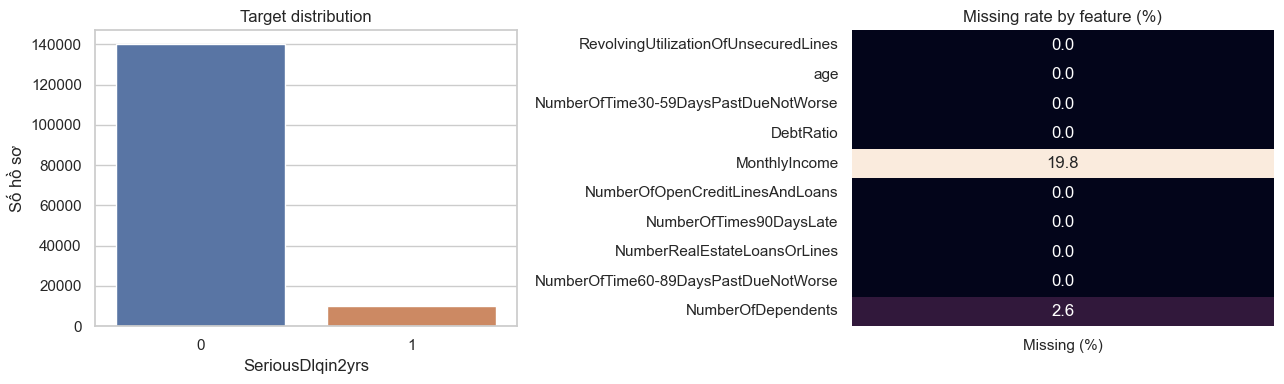

In [17]:
# Dấu hiệu bất thường: các giá trị này không nhất thiết phải xóa ngay; trước hết ghi nhận và xử lý nhất quán.
quality_checks = pd.DataFrame(index=feature_cols)
quality_checks['Số giá trị âm'] = (train[feature_cols] < 0).sum()
quality_checks['Số giá trị bằng 0'] = (train[feature_cols] == 0).sum()
quality_checks['Số giá trị vô hạn'] = np.isinf(train[feature_cols]).sum()
quality_checks['p99'] = train[feature_cols].quantile(.99)
quality_checks['p999'] = train[feature_cols].quantile(.999)
display(quality_checks)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train, x=TARGET, ax=axes[0], palette='deep')
axes[0].set_title('Target distribution')
axes[0].set_ylabel('Số hồ sơ')
sns.heatmap(train[feature_cols].isna().mean().mul(100).rename('Missing (%)').to_frame(), annot=True, fmt='.1f', cbar=False, yticklabels=True, ax=axes[1])
axes[1].set_title('Missing rate by feature (%)')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

## 3. Train/validation split và các metric đánh giá

Giữ riêng 25% số hồ sơ để kiểm định, duy trì tỷ lệ quá hạn khi chia mẫu. Các ngưỡng chia khoảng, trung vị và WOE được ước lượng trên tập train để tránh data leakage. AUC đo khả năng xếp hạng rủi ro. KS đo mức phân tách lớn nhất giữa hai nhóm khách hàng theo điểm dự báo. Hệ số Gini bằng `2 × AUC − 1`.

In [18]:
X = train[feature_cols].copy().replace([np.inf, -np.inf], np.nan)
y = train[TARGET].astype(int).copy()
X_test = test[feature_cols].copy().replace([np.inf, -np.inf], np.nan)

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_valid.shape, X_test.shape)

def ks_statistic(y_true, probability):
    fpr, tpr, _ = roc_curve(y_true, probability)
    return float(np.max(tpr - fpr))

def validation_metrics(y_true, probability, threshold=0.5):
    pred = (probability >= threshold).astype(int)
    auc = roc_auc_score(y_true, probability)
    return pd.Series({
        'AUC': auc,
        'Gini': 2 * auc - 1,
        'KS': ks_statistic(y_true, probability),
        'Brier': brier_score_loss(y_true, probability),
        'Log loss': log_loss(y_true, probability),
        f'Accuracy @ {threshold:.4g}': accuracy_score(y_true, pred),
        f'Precision @ {threshold:.4g}': precision_score(y_true, pred, zero_division=0),
        f'Recall @ {threshold:.4g}': recall_score(y_true, pred, zero_division=0),
        f'F1 @ {threshold:.4g}': f1_score(y_true, pred, zero_division=0),
    })

def plot_roc(y_true, probability, label):
    fpr, tpr, _ = roc_curve(y_true, probability)
    plt.plot(fpr, tpr, label=f'{label} (AUC={roc_auc_score(y_true, probability):.4f})')

def plot_calibration(y_true, probability, label, n_bins=10):
    observed, predicted = calibration_curve(y_true, probability, n_bins=n_bins, strategy='quantile')
    plt.plot(predicted, observed, marker='o', label=label)

(112500, 10) (37500, 10) (101503, 10)


## 4. Binning, Weight of Evidence (WOE) và Information Value (IV)

Trong mỗi khoảng, WOE là logarit của tỷ số giữa hai tỷ trọng: phần khách hàng không quá hạn thuộc khoảng đó và phần khách hàng quá hạn thuộc khoảng đó. IV tổng hợp mức phân tách của các khoảng để hỗ trợ sàng lọc biến. Khi chọn biến, cần xét cả ý nghĩa tín dụng và độ ổn định.

In [19]:
def fit_woe(X_fit, y_fit, max_bins=10, smoothing=0.5):
    edges_by_feature, woe_by_feature, iv_rows = {}, {}, []
    y_fit = pd.Series(y_fit, index=X_fit.index).astype(int)
    for col in X_fit.columns:
        x = pd.to_numeric(X_fit[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
        non_missing = x.dropna()
        if non_missing.nunique() <= 1:
            edges = np.array([-np.inf, np.inf])
        else:
            quantiles = np.linspace(0, 1, max_bins + 1)[1:-1]
            cuts = np.unique(non_missing.quantile(quantiles).to_numpy())
            edges = np.r_[-np.inf, cuts, np.inf]
        bins = pd.cut(x, bins=edges, labels=False, include_lowest=True).astype('float')
        bins = bins.fillna(-1).astype(int)
        bin_values = sorted(bins.unique())
        total_bad = max((y_fit == 1).sum(), 1)
        total_good = max((y_fit == 0).sum(), 1)
        table = pd.DataFrame({'bin': bins, 'target': y_fit}).groupby('bin')['target'].agg(['sum', 'count'])
        table['bad_n'] = table['sum']
        table['good_n'] = table['count'] - table['sum']
        table['dist_bad'] = (table['bad_n'] + smoothing) / (total_bad + smoothing * len(table))
        table['dist_good'] = (table['good_n'] + smoothing) / (total_good + smoothing * len(table))
        table['woe'] = np.log(table['dist_good'] / table['dist_bad'])
        table['iv_component'] = (table['dist_good'] - table['dist_bad']) * table['woe']
        edges_by_feature[col] = edges
        woe_by_feature[col] = table['woe'].to_dict()
        iv_rows.append({'Feature': col, 'IV': table['iv_component'].sum(), 'Number of bins': len(table)})
    return edges_by_feature, woe_by_feature, pd.DataFrame(iv_rows).sort_values('IV', ascending=False)

def transform_woe(X_new, edges_by_feature, woe_by_feature):
    output = pd.DataFrame(index=X_new.index)
    for col, edges in edges_by_feature.items():
        x = pd.to_numeric(X_new[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
        bins = pd.cut(x, bins=edges, labels=False, include_lowest=True).astype('float')
        bins = bins.fillna(-1).astype(int)
        mapping = woe_by_feature[col]
        output[col] = bins.map(mapping).fillna(0.0).astype(float)
    return output

edges, woe_maps, iv_table = fit_woe(X_train, y_train, max_bins=10)
X_train_woe = transform_woe(X_train, edges, woe_maps)
X_valid_woe = transform_woe(X_valid, edges, woe_maps)
X_test_woe = transform_woe(X_test, edges, woe_maps)
display(iv_table)

,Feature,IV,Number of bins
0,RevolvingUtilizationOfUnsecuredLines,1.107791,10
6,NumberOfTimes90DaysLate,0.843773,2
2,NumberOfTime30-59DaysPastDueNotWorse,0.725336,3
8,NumberOfTime60-89DaysPastDueNotWorse,0.574609,2
1,age,0.241668,10
3,DebtRatio,0.074544,10
4,MonthlyIncome,0.072272,11
5,NumberOfOpenCreditLinesAndLoans,0.066984,10
7,NumberRealEstateLoansOrLines,0.056131,4
9,NumberOfDependents,0.034500,5


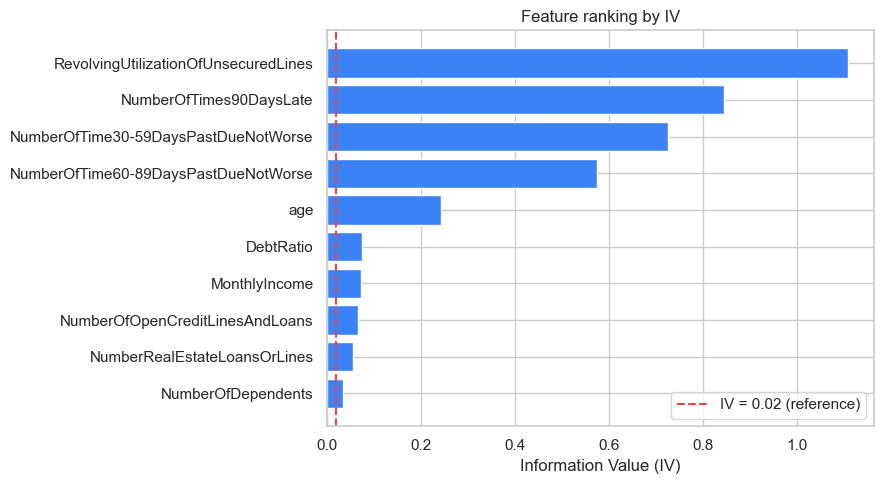

,Bad rate,Số hồ sơ,WOE
Bin,,,
0,0.024622,11250,1.041831
1,0.014043,11251,1.612773
2,0.014490,11249,1.581084
3,0.020089,11250,1.249544
4,0.023022,11250,1.110534
5,0.033333,11250,0.730423
6,0.052711,11250,0.252395
7,0.088711,11250,-0.306564
8,0.165778,11250,-1.019950


In [20]:
plt.figure(figsize=(9, 5))
top_iv = iv_table.head(15).sort_values('IV')
plt.barh(top_iv['Feature'], top_iv['IV'], color='#3b82f6')
plt.axvline(0.02, color='#ef4444', linestyle='--', label='IV = 0.02 (reference)')
plt.title('Feature ranking by IV')
plt.xlabel('Information Value (IV)')
plt.legend()
plt.tight_layout()
plt.show()

# Phân tích WOE theo từng khoảng của biến tín dụng
profile_feature = 'RevolvingUtilizationOfUnsecuredLines' if 'RevolvingUtilizationOfUnsecuredLines' in feature_cols else feature_cols[0]
x_profile = pd.to_numeric(X_train[profile_feature], errors='coerce').replace([np.inf, -np.inf], np.nan)
profile_bins = pd.cut(x_profile, bins=edges[profile_feature], labels=False, include_lowest=True).astype('float').fillna(-1).astype(int)
profile = pd.DataFrame({'bin': profile_bins, 'target': y_train}).groupby('bin').agg(bad_rate=('target','mean'), count=('target','size'))
profile['woe'] = profile.index.map(woe_maps[profile_feature])
display(profile.rename_axis('Bin').rename(columns={'bad_rate': 'Bad rate', 'count': 'Số hồ sơ', 'woe': 'WOE'}))

## 5. So sánh scorecard với benchmark

Scorecard dùng Logistic Regression trên các biến đã mã hóa WOE. Mô hình benchmark dùng HistGradientBoosting sau khi điền giá trị thiếu. So sánh trên cùng tập validation giúp đánh giá mức cải thiện về khả năng phân biệt khi dùng mô hình phi tuyến.

,WOE Logistic Scorecard,HistGradientBoosting
AUC,0.85869,0.86814
Gini,0.71738,0.73628
KS,0.56096,0.57986
Brier,0.05031,0.04871
Log loss,0.18260,0.17639
Accuracy @ 0.5,0.93584,0.93792
Precision @ 0.5,0.55938,0.61294
Recall @ 0.5,0.18795,0.19274
F1 @ 0.5,0.28136,0.29326


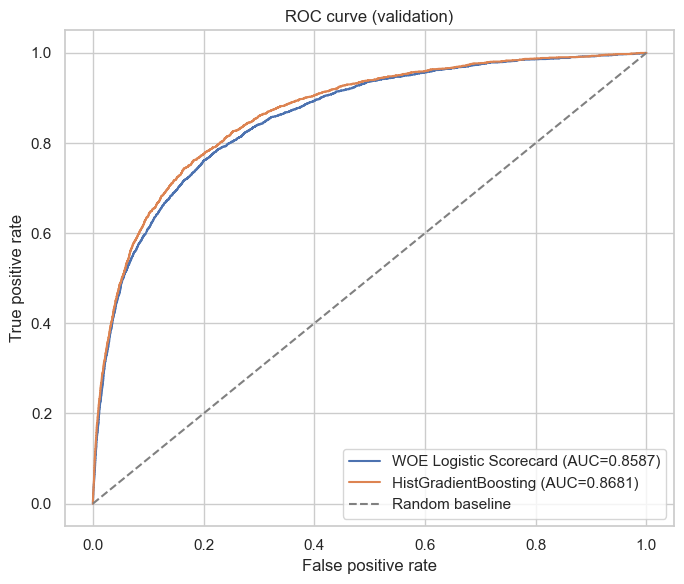

In [21]:
scorecard = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=0.5, max_iter=1000, class_weight=None, random_state=RANDOM_STATE))
])
scorecard.fit(X_train_woe, y_train)
p_scorecard = scorecard.predict_proba(X_valid_woe)[:, 1]

benchmark = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('model', HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.06, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=RANDOM_STATE
    ))
])
benchmark.fit(X_train, y_train)
p_benchmark = benchmark.predict_proba(X_valid)[:, 1]

comparison = pd.concat([
    validation_metrics(y_valid, p_scorecard).rename('WOE Logistic Scorecard'),
    validation_metrics(y_valid, p_benchmark).rename('HistGradientBoosting')
], axis=1)
display(comparison.round(5))

plt.figure(figsize=(7, 6))
plot_roc(y_valid, p_scorecard, 'WOE Logistic Scorecard')
plot_roc(y_valid, p_benchmark, 'HistGradientBoosting')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Random baseline')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curve (validation)'); plt.legend(); plt.tight_layout(); plt.show()

### Chọn decision threshold theo mục tiêu kinh doanh

Ngưỡng minh họa tối đa hóa chỉ số J của Youden, bằng độ nhạy cộng độ đặc hiệu trừ một. Khi phê duyệt tín dụng, cần cân nhắc tổn thất do bỏ sót khách hàng rủi ro, chi phí từ chối nhầm và khẩu vị rủi ro.

Ngưỡng theo chỉ số J của Youden: 0.0666
Các chỉ số tại ngưỡng đã chọn:


AUC                    0.85869
Gini                   0.71738
KS                     0.56096
Brier                  0.05031
Log loss               0.18260
Accuracy @ 0.06659     0.79635
Precision @ 0.06659    0.21338
Recall @ 0.06659       0.76217
F1 @ 0.06659           0.33342
dtype: float64

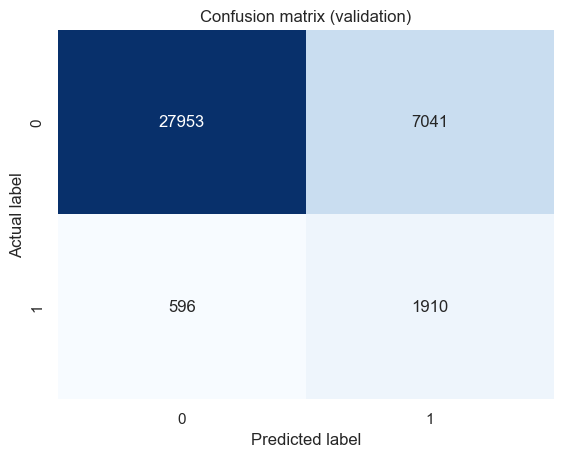

In [22]:
fpr, tpr, thresholds = roc_curve(y_valid, p_scorecard)
j = tpr - fpr
best_idx = np.argmax(j)
best_threshold = float(thresholds[best_idx])
print(f'Ngưỡng theo chỉ số J của Youden: {best_threshold:.4f}')
print('Các chỉ số tại ngưỡng đã chọn:')
display(validation_metrics(y_valid, p_scorecard, threshold=best_threshold).round(5))

cm = confusion_matrix(y_valid, (p_scorecard >= best_threshold).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted label'); plt.ylabel('Actual label'); plt.title('Confusion matrix (validation)')
plt.show()

## 6. Calibration và hệ số của scorecard

Calibration curve so sánh xác suất dự báo trung bình với tỷ lệ quá hạn thực tế trong từng nhóm. Hai giá trị càng gần nhau, xác suất dự báo của nhóm càng sát thực tế. Khi đọc hệ số hồi quy, cần đối chiếu dấu của hệ số với quy ước tính WOE.

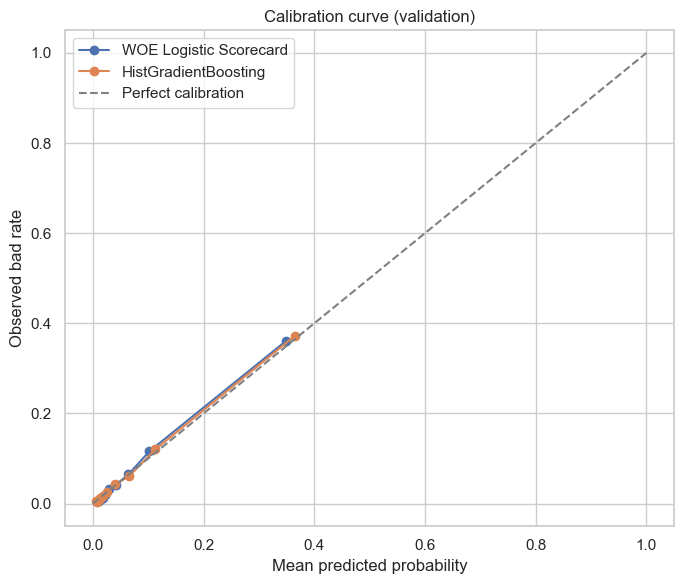

,Hệ số hồi quy
RevolvingUtilizationOfUnsecuredLines,-0.638828
NumberOfTime30-59DaysPastDueNotWorse,-0.343965
NumberOfTimes90DaysLate,-0.329266
NumberOfTime60-89DaysPastDueNotWorse,-0.214576
DebtRatio,-0.208357
age,-0.207745
NumberRealEstateLoansOrLines,-0.140826
NumberOfDependents,-0.043362
MonthlyIncome,-0.021671
NumberOfOpenCreditLinesAndLoans,0.011695


In [23]:
plt.figure(figsize=(7, 6))
plot_calibration(y_valid, p_scorecard, 'WOE Logistic Scorecard')
plot_calibration(y_valid, p_benchmark, 'HistGradientBoosting')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed bad rate')
plt.title('Calibration curve (validation)'); plt.legend(); plt.tight_layout(); plt.show()

coef = pd.Series(scorecard.named_steps['model'].coef_[0], index=feature_cols)
coef_table = coef.sort_values().to_frame('Hệ số hồi quy')
display(coef_table)

# Khi các biến khác giữ nguyên, hệ số dương nghĩa là WOE cao hơn đi cùng xác suất quá hạn dự báo cao hơn.
# Đối chiếu dấu hệ số với cách tính WOE và ý nghĩa nghiệp vụ của biến.

## 7. Đánh giá độ ổn định của dữ liệu đầu vào bằng PSI

Population Stability Index (PSI) so sánh phân phối từng biến giữa tập train và tập test. Các mốc 0,10 và 0,25 là ngưỡng tham khảo để xác định biến cần xem xét. Muốn kết luận mô hình dự báo kém đi, cần có kết quả trả nợ thực tế.

,Feature,PSI (train vs. test),Nhận xét
4,MonthlyIncome,0.000426,Biến động thấp
1,age,0.000174,Biến động thấp
0,RevolvingUtilizationOfUnsecuredLines,0.000172,Biến động thấp
9,NumberOfDependents,0.000147,Biến động thấp
7,NumberRealEstateLoansOrLines,0.000105,Biến động thấp
3,DebtRatio,0.000087,Biến động thấp
5,NumberOfOpenCreditLinesAndLoans,0.000074,Biến động thấp
2,NumberOfTime30-59DaysPastDueNotWorse,0.000023,Biến động thấp
6,NumberOfTimes90DaysLate,0.000000,Biến động thấp
8,NumberOfTime60-89DaysPastDueNotWorse,0.000000,Biến động thấp


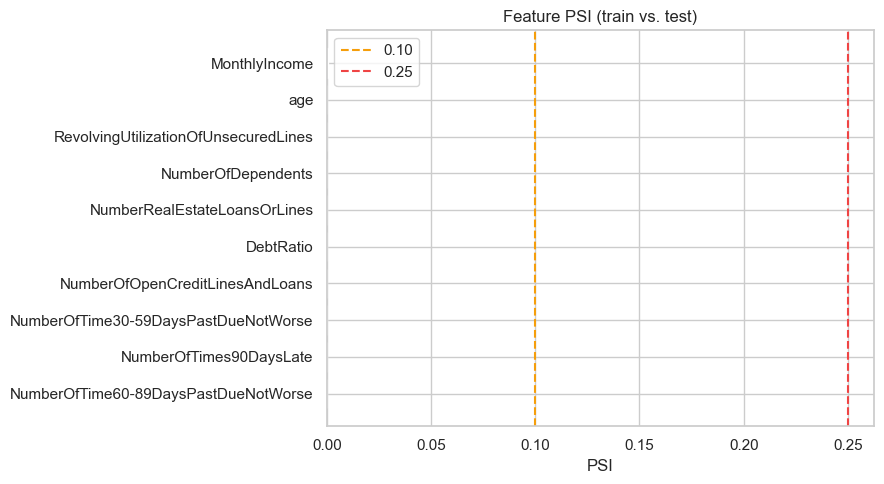

In [24]:
def psi_numeric(reference, current, bins=10, epsilon=1e-6):
    reference = pd.to_numeric(pd.Series(reference), errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
    current = pd.to_numeric(pd.Series(current), errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
    if reference.nunique() <= 1:
        return 0.0
    edges = np.unique(np.nanquantile(reference, np.linspace(0, 1, bins + 1)))
    if len(edges) < 2:
        return 0.0
    edges = np.r_[-np.inf, edges[1:-1], np.inf]
    ref_dist = pd.cut(reference, edges, include_lowest=True).value_counts(normalize=True, sort=False)
    cur_dist = pd.cut(current, edges, include_lowest=True).value_counts(normalize=True, sort=False)
    ref_dist = ref_dist.clip(lower=epsilon)
    cur_dist = cur_dist.reindex(ref_dist.index, fill_value=epsilon).clip(lower=epsilon)
    return float(((cur_dist - ref_dist) * np.log(cur_dist / ref_dist)).sum())

psi_table = pd.DataFrame({
    'Feature': feature_cols,
    'PSI (train vs. test)': [psi_numeric(X_train[c], X_test[c]) for c in feature_cols]
}).sort_values('PSI (train vs. test)', ascending=False)
psi_table['Nhận xét'] = pd.cut(
    psi_table['PSI (train vs. test)'],
    bins=[-np.inf, 0.10, 0.25, np.inf],
    labels=['Biến động thấp', 'Biến động vừa, cần tìm nguyên nhân', 'Biến động lớn, cần báo cáo']
)
display(psi_table)

plt.figure(figsize=(9, 5))
psi_plot = psi_table.head(15).sort_values('PSI (train vs. test)')
plt.barh(psi_plot['Feature'], psi_plot['PSI (train vs. test)'], color='#8b5cf6')
plt.axvline(.10, color='#f59e0b', linestyle='--', label='0.10')
plt.axvline(.25, color='#ef4444', linestyle='--', label='0.25')
plt.xlabel('PSI'); plt.title('Feature PSI (train vs. test)'); plt.legend(); plt.tight_layout(); plt.show()

## 8. Tổng hợp kết quả kiểm định và theo dõi theo thời gian

Dữ liệu thiếu thời điểm quan sát để thực hiện out-of-time validation. Khi có dữ liệu vận hành, nên theo dõi tỷ lệ thiếu và PSI theo tháng hoặc quý. Khi khoản vay đã đủ thời gian quan sát, tính lại AUC, Gini, KS, tỷ lệ quá hạn và đối chiếu xác suất dự báo với kết quả thực tế.

In [25]:
# Tổng hợp chỉ số để rà soát kết quả kiểm định
validation_report = pd.DataFrame({
    'Nội dung kiểm định': [
        'Bad rate', 'AUC trên tập validation', 'Gini trên tập validation', 'KS trên tập validation',
        'Brier score trên tập validation', 'Log loss trên tập validation', 'Số biến có IV >= 0.02',
        'Số biến có PSI >= 0.10', 'Số biến có PSI >= 0.25'
    ],
    'Giá trị': [
        y.mean(), roc_auc_score(y_valid, p_scorecard), 2 * roc_auc_score(y_valid, p_scorecard) - 1,
        ks_statistic(y_valid, p_scorecard), brier_score_loss(y_valid, p_scorecard),
        log_loss(y_valid, p_scorecard), (iv_table['IV'] >= .02).sum(),
        (psi_table['PSI (train vs. test)'] >= .10).sum(), (psi_table['PSI (train vs. test)'] >= .25).sum()
    ]
})
display(validation_report)

print('Nội dung cần rà soát:')
print('- Thống nhất định nghĩa quá hạn và thời gian quan sát với bộ phận nghiệp vụ.')
print('- Kiểm tra data leakage, thay đổi chính sách và sai lệch chọn mẫu do chỉ quan sát kết quả của người được duyệt vay.')
print('- Đánh giá tính công bằng và tác động theo nhóm khách hàng khi có dữ liệu phù hợp.')
print('- Đặt ngưỡng cảnh báo và phân công người xử lý khi giám sát mô hình vận hành.')

,Nội dung kiểm định,Giá trị
0,Bad rate,0.066840
1,AUC trên tập validation,0.858692
2,Gini trên tập validation,0.717383
3,KS trên tập validation,0.560965
4,Brier score trên tập validation,0.050309
5,Log loss trên tập validation,0.182605
6,Số biến có IV >= 0.02,10.000000
7,Số biến có PSI >= 0.10,0.000000
8,Số biến có PSI >= 0.25,0.000000


Nội dung cần rà soát:
- Thống nhất định nghĩa quá hạn và thời gian quan sát với bộ phận nghiệp vụ.
- Kiểm tra data leakage, thay đổi chính sách và sai lệch chọn mẫu do chỉ quan sát kết quả của người được duyệt vay.
- Đánh giá tính công bằng và tác động theo nhóm khách hàng khi có dữ liệu phù hợp.
- Đặt ngưỡng cảnh báo và phân công người xử lý khi giám sát mô hình vận hành.


## 9. Refit mô hình và tạo file submission

Sau khi chọn mô hình, ước lượng lại WOE và hệ số hồi quy trên toàn bộ mẫu có nhãn. Cột `Probability` trong file submission chứa xác suất quá hạn của từng khách hàng.

In [26]:
# Ước lượng lại WOE trên toàn bộ tập train sau khi chọn mô hình.
full_edges, full_woe_maps, full_iv = fit_woe(X, y, max_bins=10)
X_full_woe = transform_woe(X, full_edges, full_woe_maps)
X_test_full_woe = transform_woe(X_test, full_edges, full_woe_maps)

final_scorecard = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=0.5, max_iter=1000, random_state=RANDOM_STATE))
])
final_scorecard.fit(X_full_woe, y)
test_probability = final_scorecard.predict_proba(X_test_full_woe)[:, 1]

if sample_submission is not None and 'Probability' in sample_submission.columns:
    submission = sample_submission.copy()
    submission['Probability'] = test_probability
else:
    submission = pd.DataFrame({'Id': test['Id'] if 'Id' in test.columns else np.arange(len(test)),
                               'Probability': test_probability})

submission_path = Path('submission_scorecard.csv')
submission.to_csv(submission_path, index=False)
print(f'Đã lưu: {submission_path.resolve()}')
display(submission.head())
print(submission['Probability'].describe())

Đã lưu: D:\Desktop\Give Me Some Credit\submission_scorecard.csv


,Id,Probability
0,1,0.078382
1,2,0.057305
2,3,0.018855
3,4,0.110600
4,5,0.108036


count    101503.000000
mean          0.067132
std           0.116539
min           0.005387
25%           0.014322
50%           0.025546
75%           0.064126
max           0.898868
Name: Probability, dtype: float64


## 10. Kết luận và giới hạn sử dụng

- **Khả năng phân biệt** — Đối chiếu AUC, Gini và KS của hai mô hình trên cùng tập validation.
- **Độ chính xác của xác suất dự báo** — Xem Brier score, log loss và calibration curve. Nếu điều chỉnh xác suất, dành một mẫu riêng để đánh giá sau điều chỉnh.
- **Độ ổn định** — Xem PSI cùng tỷ lệ thiếu của từng biến. Dữ liệu hiện tại chỉ cho phép so sánh giữa hai mẫu tại thời điểm phân tích.
- **Khả năng giải thích** — Đối chiếu WOE, dấu hệ số và tỷ lệ quá hạn theo khoảng với hiểu biết nghiệp vụ.
- **Quản trị mô hình** — Ghi lại phiên bản dữ liệu, random seed, giả định, ngưỡng quyết định, người phụ trách và biện pháp xử lý khi có cảnh báo.

Mẫu chia ngẫu nhiên chưa cho biết mô hình hoạt động ra sao ở kỳ sau. Dữ liệu cũng thiếu thông tin về chính sách tín dụng và người bị từ chối vay. Khi triển khai, cần lưu phiên bản các ngưỡng chia khoảng và quy tắc xử lý giá trị thiếu để áp dụng nhất quán.